# 02 — Modeling: dari data bersih sampai model siap pakai

Lanjutan dari `01_eda.ipynb`. Notebook ini menjalankan alur yang sama dengan `python -m src.train`, tapi **langkah demi langkah** supaya setiap hasil antara bisa dilihat.

Alur:
1. Load & clean
2. Split train/test
3. Lihat isi feature (TF-IDF + TextStats)
4. Bandingkan model dengan cross-validation
5. Latih model terpilih
6. Evaluasi di test set
7. Atur threshold
8. Error analysis
9. Interpretasi
10. Simpan & pakai model

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, precision_score, recall_score, f1_score
from src.config import DATA_PATH, MODEL_PATH, TEXT_COL, LABEL_COL
from src.preprocessing import load_data, clean_data
from src.model import build_features, build_pipeline, compare_models, get_candidate_models, select_best_model, split_data
from src.evaluation import evaluate_model, top_features, error_analysis
pd.set_option('display.max_colwidth', 100)
%matplotlib inline

## 1. Load & clean
`clean_data()` membuang kolom bocoran (`predicted_label`) dan duplikat **sebelum** split.

In [2]:
df = clean_data(load_data(DATA_PATH))
print(df.shape)
df[LABEL_COL].value_counts()

(9001, 7)


label
0    6018
1    2983
Name: count, dtype: int64

## 2. Split train/test
`stratify` menjaga rasio judol:normal sama. **Test set tidak disentuh sampai langkah 6.**

In [3]:
X_train, X_test, y_train, y_test = split_data(df[TEXT_COL], df[LABEL_COL])
print(f'train={len(X_train)}  test={len(X_test)}')
pd.DataFrame({'train': y_train.value_counts(normalize=True), 'test': y_test.value_counts(normalize=True)}).round(3)

train=7200  test=1801


,train,test
label,,
0,0.669,0.669
1,0.331,0.331


## 3. Seperti apa feature-nya?
Kita `fit` feature pada train saja, lalu lihat ukurannya dan contoh nilai untuk satu komentar.

In [4]:
features = build_features().fit(X_train)
names = features.get_feature_names_out()
print('jumlah feature:', len(names))
pd.Series([n.split('__')[0] for n in names]).value_counts()

jumlah feature: 37699


char     30030
word      7663
stats        6
Name: count, dtype: int64

In [5]:
contoh = 'gacor parah di 𝐒𝐆𝐈𝟖𝟖 , mantap'
vec = features.transform([contoh]).toarray()[0]
nonzero = pd.Series(vec, index=names)[vec > 0].sort_values(ascending=False)
print(f'{len(nonzero)} dari {len(names)} feature bernilai > 0 (sparse!)')
nonzero.head(15)

96 dari 37699 feature bernilai > 0 (sparse!)


word__gacor parah            0.510763
stats__brand_number_count    0.500000
word__di sgi88               0.461949
stats__log_length            0.379680
word__parah                  0.370886
word__gacor                  0.367533
word__mantap                 0.332515
word__sgi88                  0.308820
word__di                     0.217143
stats__styled_char_ratio     0.201149
stats__digit_ratio           0.160920
char__arah                   0.149557
char__acor                   0.148698
char__parah                  0.148279
char__cor                    0.147866
dtype: float64

Hampir semua nilai 0. Inilah **sparse matrix**: scikit-learn hanya menyimpan nilai yang bukan 0, sehingga hemat memori.

## 4. Bandingkan model (5-fold CV, train saja)
Random Forest paling lambat, sekitar 1 menit.

In [6]:
models = get_candidate_models()
cv_results = compare_models(X_train, y_train, models)
cv = pd.DataFrame(cv_results).T
cv.round(4)

  naive_bayes          F1=0.9714 ± 0.0044


  logistic_regression  F1=0.9818 ± 0.0067


  linear_svm           F1=0.9825 ± 0.0048


  random_forest        F1=0.9826 ± 0.0066


,accuracy,precision,recall,f1,f1_std,fit_seconds
naive_bayes,0.9808,0.9615,0.9816,0.9714,0.0044,0.8595
logistic_regression,0.9881,0.9910,0.9728,0.9818,0.0067,0.9814
linear_svm,0.9885,0.9894,0.9757,0.9825,0.0048,0.8502
random_forest,0.9886,0.9936,0.9719,0.9826,0.0066,1.7592


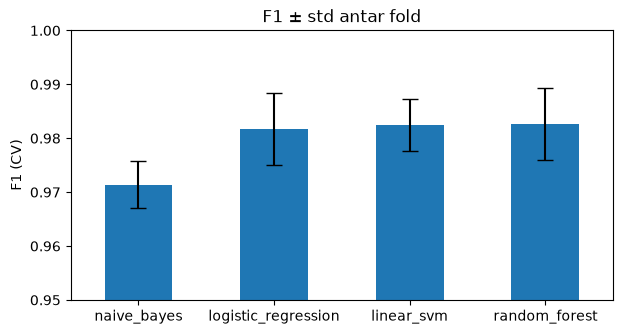

In [7]:
ax = cv['f1'].plot.bar(yerr=cv['f1_std'], capsize=6, rot=0, figsize=(7, 3.5))
ax.set_ylim(0.95, 1.0); ax.set_ylabel('F1 (CV)'); ax.set_title('F1 ± std antar fold');

Batang error (std) saling tumpang tindih → selisih antar model teratas hanyalah noise. Pakai **one-standard-error rule**: pilih model paling sederhana yang masih dalam 1 std dari yang terbaik.

In [8]:
best_name = select_best_model(cv_results)
best_name

'logistic_regression'

## 5. Latih model terpilih di seluruh train set

In [9]:
model = build_pipeline(models[best_name])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word', ...), ('char', ...), ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


## 6. Evaluasi di test set (sekali saja!)

In [10]:
metrics = evaluate_model(model, X_test, y_test)
print(metrics['report'])
print('ROC-AUC:', round(metrics['roc_auc'], 4))

              precision    recall  f1-score   support

      normal     0.9909    0.9958    0.9934      1204
       judol     0.9915    0.9816    0.9865       597

    accuracy                         0.9911      1801
   macro avg     0.9912    0.9887    0.9900      1801
weighted avg     0.9911    0.9911    0.9911      1801

ROC-AUC: 0.9994


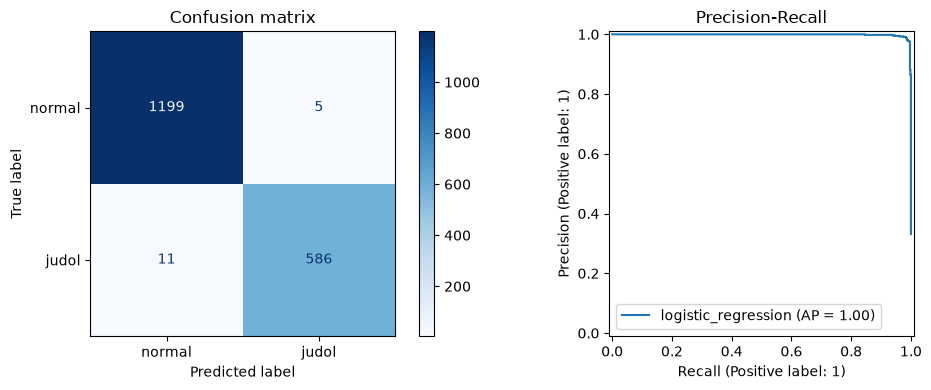

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['normal', 'judol'], cmap='Blues', ax=axes[0])
PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1], name=best_name)
axes[0].set_title('Confusion matrix'); axes[1].set_title('Precision-Recall'); plt.tight_layout()

Pembanding: model "bodoh" yang selalu menebak normal.

In [12]:
print('accuracy baseline:', round((y_test == 0).mean(), 3), ' | recall judol baseline: 0.0')

accuracy baseline: 0.669  | recall judol baseline: 0.0


## 7. Mengatur threshold
Default: skor ≥ 0,5 → judol. Geser threshold untuk menukar precision dengan recall.

In [13]:
scores = model.predict_proba(X_test)[:, 1]
rows = []
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred = (scores >= t).astype(int)
    rows.append({'threshold': t, 'precision': precision_score(y_test, pred), 'recall': recall_score(y_test, pred),
                 'f1': f1_score(y_test, pred), 'salah_hapus (FP)': int(((pred == 1) & (y_test == 0)).sum()),
                 'spam_lolos (FN)': int(((pred == 0) & (y_test == 1)).sum())})
pd.DataFrame(rows).round(4)

,threshold,precision,recall,f1,salah_hapus (FP),spam_lolos (FN)
0,0.1,0.9475,0.9966,0.9714,33,2
1,0.3,0.9801,0.9883,0.9842,12,7
2,0.5,0.9915,0.9816,0.9865,5,11
3,0.7,0.9915,0.9749,0.9831,5,15
4,0.9,0.9982,0.9363,0.9663,1,38


## 8. Error analysis
Baca komentar yang salah ditebak. Mana yang penyamaran baru, mana yang labelnya salah?

In [14]:
errors = error_analysis(model, X_test, y_test)
errors['score'] = model.predict_proba(errors['komentar'])[:, 1].round(3)
print(errors['error_type'].value_counts().to_dict())
errors.sort_values('error_type')

{'false_negative': 11, 'false_positive': 5}


,komentar,label,predicted,error_type,score
3271,semoga amal ibadahnya terima sisi tuhan,1,0,false_negative,0.046
813,gilaa berubah dratis cok main,1,0,false_negative,0.295
7970,ubur ubur ikan lele 𝑷𝑶𝑲𝑬𝑹𝑩𝑶𝑳𝑨 mantap le !,1,0,false_negative,0.193
3918,lengkap kalo chery bikin dealer pangkalan bun .,1,0,false_negative,0.239
2928,"maen ps 5 tv 5,5 inci udh lumayan bagus sih wkwkw",1,0,false_negative,0.366
3580,keren . gas mari kak 𝐒 𝙂ｉ𝟖 𝟖,1,0,false_negative,0.388
2356,"Gila sih, Gak bisa move on dari serunya 🔥⚡𝒥 𝟤 𝟢 𝟢 𝑀⚡?🔥.",1,0,false_negative,0.217
2612,"𝙈𝗮𝘯𝐝𝘼L!K𝘼7𝟟 itu tempatnya para jagoan judi, jadi lu nggak cuma main, tapi juga bisa belajar dari...",1,0,false_negative,0.239
1773,wadidaw kren bgt yak depo 50 doan jd 2jt wwk💫💫,1,0,false_negative,0.040
5645,coba langsung ngerti suka,1,0,false_negative,0.423


## 9. Interpretasi: apa yang dipelajari model?
Bobot positif → mendorong ke judol, negatif → ke normal.

In [15]:
top = top_features(model, n=15)
pd.DataFrame({'→ judol': [f'{n} ({w:+.1f})' for n, w in top['judol']],
              '→ normal': [f'{n} ({w:+.1f})' for n, w in top['normal']]})

,→ judol,→ normal
0,stats__brand_number_count (+12.0),word__user (-4.1)
1,stats__styled_char_ratio (+7.4),word__bang (-2.9)
2,stats__log_length (+6.0),char__😂 (-2.8)
3,"char__ , (+4.8)",char__.. (-2.4)
4,word__alexis (+4.7),word__mas (-2.3)
5,"char__ , (+4.7)",word__hp (-2.3)
6,word__alexis 17 (+4.3),word__ada (-2.1)
7,word__777 (+4.0),word__bg (-2.0)
8,word__77 (+3.9),word__pak (-2.0)
9,word__17 (+3.8),char__ 😂 (-1.9)


Perhatikan: banyak feature judol adalah **nama situs spesifik** (alexis, 777). Model mungkin kesulitan dengan situs baru. Ini diuji di `03_tuning_robustness_deployment.ipynb`.

## 10. Simpan & pakai model

In [16]:
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(model, MODEL_PATH)
loaded = joblib.load(MODEL_PATH)
komentar_baru = ['mantap videonya bang, lanjutkan', 'sehari maxwin di Ｐｕｌａｕ７７７', 'k o i s l o t bikin aku sultan',
                 'mobilnya keren banget, berapa harganya?', 'jp terus di ᗩᗷGᗯIᑎ']
pd.DataFrame({'komentar': komentar_baru, 'prediksi': np.where(loaded.predict(komentar_baru) == 1, 'judol', 'normal'),
              'skor_judol': loaded.predict_proba(komentar_baru)[:, 1].round(3)})

,komentar,prediksi,skor_judol
0,"mantap videonya bang, lanjutkan",normal,0.005
1,sehari maxwin di Ｐｕｌａｕ７７７,judol,1.000
2,k o i s l o t bikin aku sultan,judol,0.737
3,"mobilnya keren banget, berapa harganya?",normal,0.005
4,jp terus di ᗩᗷGᗯIᑎ,judol,0.948


## Ringkasan
- Pipeline: normalisasi Unicode → TF-IDF word + char + TextStats → Logistic Regression
- Dipilih lewat 5-fold CV + one-standard-error rule, dievaluasi **sekali** di test set
- F1 judol ≈ 0,987, tapi waspadai ketergantungan pada nama situs yang sudah dikenal
- Langkah berikutnya: tuning (`GridSearchCV`), uji situs baru, coba IndoBERT